<a href="https://colab.research.google.com/github/PedroMoreira191/CN/blob/main/Atividade2_CN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Pedro Oliveira 188198 - Felipe Silva 185606

Definições


Maior float32: 3.4028235e+38
Maior float64: 1.7976931348623157e+308
dt=0.001, float32: 120 passos sem overflow.
dt=0.002, float32: 120 passos sem overflow.
dt=0.001, float64: 120 passos sem overflow.
dt=0.002, float64: 120 passos sem overflow.


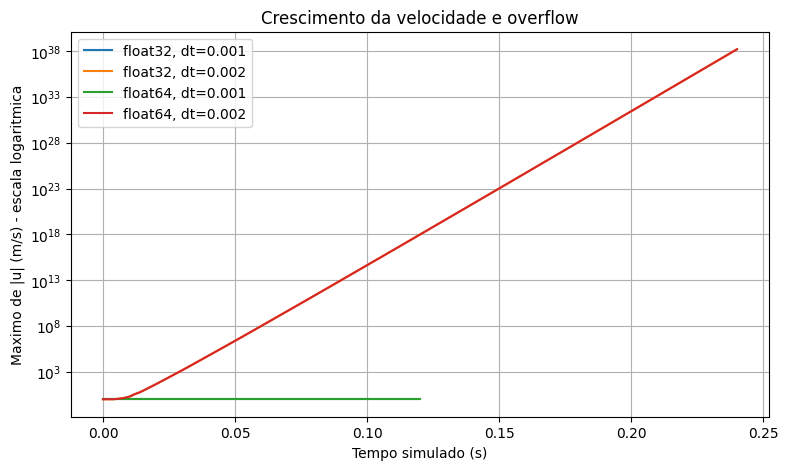

In [ ]:
import matplotlib.pyplot as plt
import numpy as np


def simular(dt, tipo=np.float32, passos=120, pontos=21):
    """Simula difusao de velocidade e detecta falhas."""
    H = 0.01
    nu = 1e-4
    y = np.linspace(0, H, pontos)
    dy = H / (pontos - 1)

    # Coeficientes no tipo numerico escolhido.
    r = tipo(nu * dt / dy**2)
    dois = tipo(2)

    # Fluido parado e placa em y=0 em movimento.
    u = np.zeros(pontos, dtype=tipo)
    u[0] = tipo(1)

    tempos = [0.0]
    maximos = [float(np.max(np.abs(u)))]
    falha = None

    # Transforma avisos numericos em excecoes.
    with np.errstate(over="raise", invalid="raise"):
        for passo in range(1, passos + 1):
            try:
                novo = u.copy()
                # Atualiza o interior e preserva as paredes.
                novo[1:-1] = u[1:-1] + r * (u[2:] - dois * u[1:-1] + u[:-2])
            except FloatingPointError as erro:
                falha = passo
                print(
                    f"dt={dt}, {tipo.__name__}: "
                    f"falha no passo {passo}, "
                    f"t={passo * dt:.4f} s - {erro}"
                )
                break

            u = novo
            tempos.append(passo * dt)
            maximos.append(float(np.max(np.abs(u))))

    if falha is None:
        print(f"dt={dt}, {tipo.__name__}: {passos} passos sem overflow.")

    return {
        "y": y,
        "u": u,
        "tempos": tempos,
        "maximos": maximos,
        "r": float(r),
        "falha": falha,
    }


print("Maior float32:", np.finfo(np.float32).max)
print("Maior float64:", np.finfo(np.float64).max)

resultados = {}
for tipo in (np.float32, np.float64):
    for dt in (0.001, 0.002):
        nome = f"{tipo.__name__}, dt={dt}"
        resultados[nome] = simular(dt, tipo)

plt.figure(figsize=(9, 5))
for nome, resultado in resultados.items():
    plt.semilogy(resultado["tempos"], resultado["maximos"], label=nome)

plt.xlabel("Tempo simulado (s)")
plt.ylabel("Maximo de |u| (m/s) - escala logaritmica")
plt.title("Crescimento da velocidade e overflow")
plt.grid(True)
plt.legend()
plt.show()

Parte 1

In [ ]:
H = 0.01
nu = 1e-4
pontos = 21
dy = H / (pontos - 1)
dt_max = (dy**2) / (2 * nu)


casos = {"Caso A": 0.001, "Caso B": 0.002}

for nome, dt in casos.items():
    r = nu * dt / (dy**2)
    classificacao = "ESTÁVEL" if r <= 0.5 else "INSTÁVEL"
    print(f"{nome} (dt={dt}s): r = {r:.4f} -> Classificação: {classificacao}")


Caso A (dt=0.001s): r = 0.4000 -> Classificação: ESTÁVEL
Caso B (dt=0.002s): r = 0.8000 -> Classificação: INSTÁVEL


Parte 2

In [ ]:


resultados_tabela = []
resultados_sim = {}


configuracoes = [
    (np.float32, 0.001),
    (np.float64, 0.001),
    (np.float32, 0.002),
    (np.float64, 0.002),
]

for tipo, dt in configuracoes:
    chave = f"{tipo.__name__}, dt={dt}"
    res = simular(dt=dt, tipo=tipo, passos=3000, pontos=21)
    resultados_sim[chave] = res

    houve_overflow = "Sim" if res["falha"] is not None else "Não"
    passo_falha = res["falha"] if res["falha"] is not None else "-"

    resultados_tabela.append({
        "Tipo Numérico": tipo.__name__,
        "dt (s)": dt,
        "Valor de r": round(res["r"], 2),
        "Overflow?": houve_overflow,
        "Iteração da Falha": passo_falha
    })

tabela_df = pd.DataFrame(resultados_tabela)

display(tabela_df)

dt=0.001, float32: 3000 passos sem overflow.
dt=0.001, float64: 3000 passos sem overflow.
dt=0.002, float32: falha no passo 121, t=0.2420 s - overflow encountered in subtract
dt=0.002, float64: falha no passo 917, t=1.8340 s - overflow encountered in add


,Tipo Numérico,dt (s),Valor de r,Overflow?,Iteração da Falha
0,float32,0.001,0.4,Não,-
1,float64,0.001,0.4,Não,-
2,float32,0.002,0.8,Sim,121
3,float64,0.002,0.8,Sim,917


Parte 3

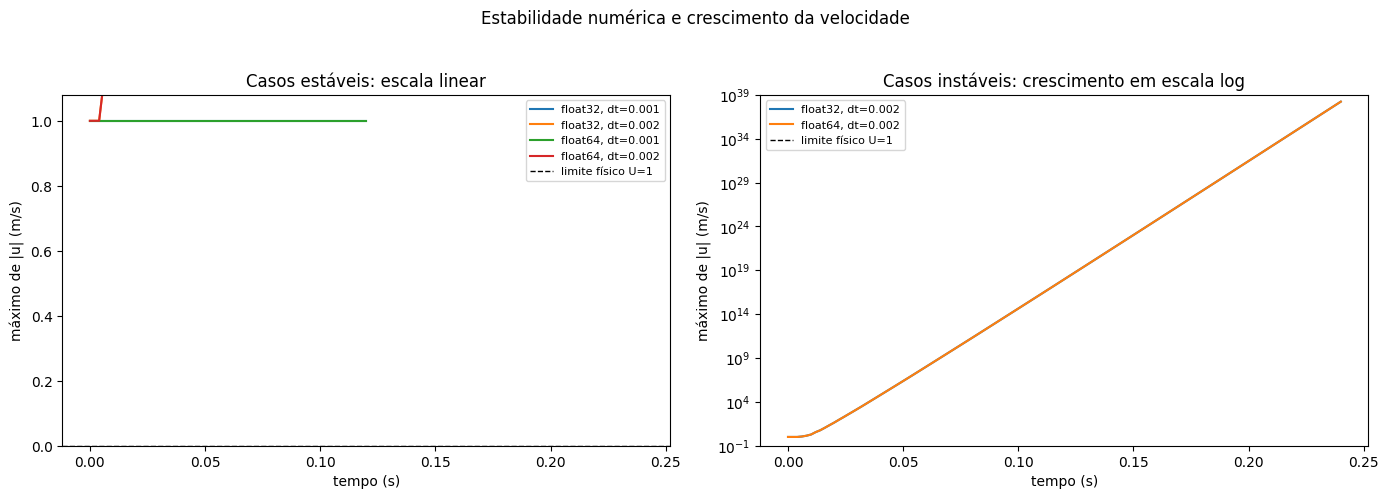

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))

for chave, resultado in resultados.items():
    axes[0].plot(resultado["tempos"], resultado["maximos"], label=chave)
axes[0].axhline(nu, color="black", linestyle="--", linewidth=1, label="limite físico U=1")
axes[0].set_title("Casos estáveis: escala linear")
axes[0].set_xlabel("tempo (s)")
axes[0].set_ylabel("máximo de |u| (m/s)")
axes[0].set_ylim(0, 1.08)
axes[0].legend(fontsize=8)

for chave, resultado in resultados.items():
    if resultado["r"] > 0.5:
        axes[1].semilogy(resultado["tempos"], resultado["maximos"], label=chave)
axes[1].axhline(nu, color="black", linestyle="--", linewidth=1, label="limite físico U=1")
axes[1].set_title("Casos instáveis: crescimento em escala log")
axes[1].set_xlabel("tempo (s)")
axes[1].set_ylabel("máximo de |u| (m/s)")
axes[1].set_ylim(1e-1, 1e39)
axes[1].legend(fontsize=8)

fig.suptitle("Estabilidade numérica e crescimento da velocidade", y=1.03)
fig.tight_layout()
plt.show()

Parte 4

--- ATIVIDADES 3 E 4: GRÁFICO DE CRESCIMENTO E OVERFLOW ---


/usr/local/lib/python3.13/dist-packages/matplotlib/scale.py:253: RuntimeWarning: overflow encountered in power
  return np.power(self.base, values)


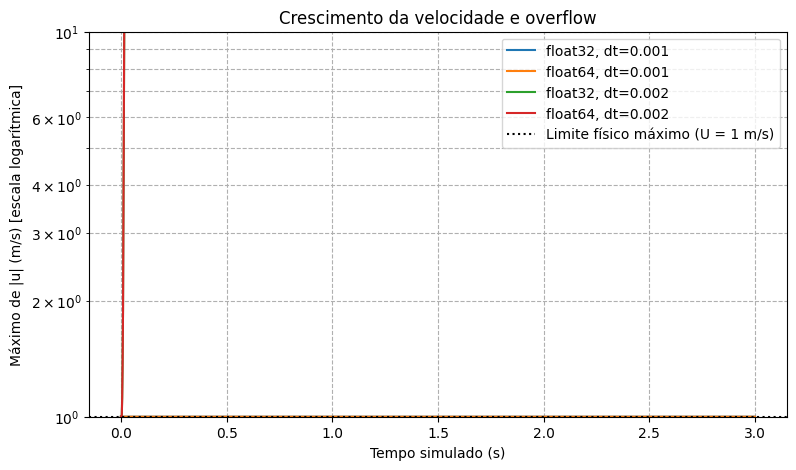


Limites máximos de ponto flutuante:
Maior float32: 3.40e+38
Maior float64: 1.80e+308


Parte 5


In [ ]:


pontos_ref = 41
dy_ref = H / (pontos_ref - 1)
dt_max_ref = (dy_ref**2) / (2 * nu)

print(f"Novo Delta y: {dy_ref:.6f} m")
print(f"Novo Delta t max: {dt_max_ref:.6f} s\n")

# Teste 1: Mantendo dt = 0.001 s (agora deve falhar)
dt_antigo = 0.001
r_antigo = nu * dt_antigo / (dy_ref**2)
print(f"Tentativa 1 com dt = {dt_antigo}s (r = {r_antigo:.2f}):")
simular(dt=dt_antigo, tipo=np.float32, passos=2000, pontos=pontos_ref)

# Teste 2: Escolhendo um dt abaixo do novo limite (ex: dt = 0.00025 s -> r = 0.4)
dt_novo = 0.00025
r_novo = nu * dt_novo / (dy_ref**2)
print(f"\nTentativa 2 com dt = {dt_novo}s (r = {r_novo:.2f}):")
res_refinada = simular(dt=dt_novo, tipo=np.float32, passos=4000, pontos=pontos_ref)

Novo Delta y: 0.000250 m
Novo Delta t max: 0.000312 s

Tentativa 1 com dt = 0.001s (r = 1.60):
dt=0.001, float32: falha no passo 56, t=0.0560 s - overflow encountered in multiply

Tentativa 2 com dt = 0.00025s (r = 0.40):
dt=0.00025, float32: 4000 passos sem overflow.


Parte 6

--- ATIVIDADE 6: PERFIL ESTACIONÁRIO E ERRO ---
dt=0.001, float64: 2000 passos sem overflow.

Diferença máxima em relação ao estacionário (E_inf): 1.6053e-09 m/s


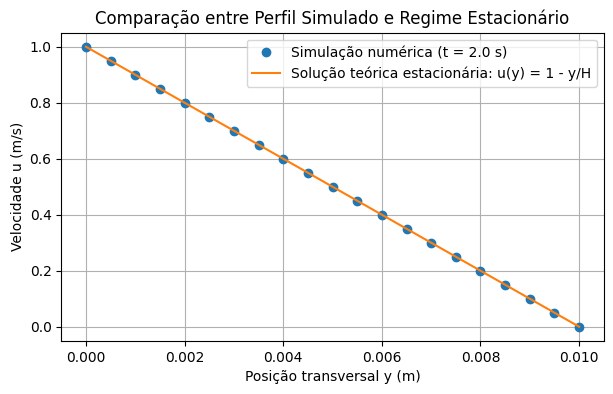

In [ ]:


# Execução estável longa com dt=0.001 e 2000 passos (t = 2.0 s)
res_estavel = simular(dt=0.001, tipo=np.float64, passos=2000, pontos=21)

y = res_estavel["y"]
u_num = res_estavel["u"]

# Perfil estacionário analítico de Couette: u_est(y) = U * (1 - y / H)
u_est = 1.0 * (1.0 - y / H)

# Erro máximo da norma infinito
E_inf = np.max(np.abs(u_num - u_est))

print(f"\nDiferença máxima em relação ao estacionário (E_inf): {E_inf:.4e} m/s")

# Gráfico de comparação
plt.figure(figsize=(7, 4))
plt.plot(y, u_num, "o", label=f"Simulação numérica (t = {res_estavel['tempos'][-1]:.1f} s)")
plt.plot(y, u_est, "-", label="Solução teórica estacionária: u(y) = 1 - y/H")
plt.xlabel("Posição transversal y (m)")
plt.ylabel("Velocidade u (m/s)")
plt.title("Comparação entre Perfil Simulado e Regime Estacionário")
plt.grid(True)
plt.legend()
plt.show()

Parte 7

O refinamento da malha melhora a resolução espacial, mas reduz o passo de tempo permitido: $Δt_{max} = \frac{Δy²}{2ν}$. Se Δt for mantido grande após o refinamento, $r$ ultrapassa 1/2, o coeficiente central torna-se negativo e a solução pode oscilar e crescer.

A instabilidade numérica é a causa primária da solução incorreta; o overflow é uma falha posterior de representação. A alteração que corrige a causa é escolher $Δt$ de forma que $r$ ≤ 1/2 (e repetir esse ajuste quando a malha for refinada). Alterar apenas $float32$ para $float64$ aumenta a faixa numérica, mas não corrige o método.